# Clearnet correlation: client Guard vs Exit

**Question.** An observer sees the traffic between a Tor client and its Guard, and between the Exit and a web server. Can it tell, by timing alone, that the two belong to the same requests?

**Setup.** Private Tor network in Docker: 3 directory authorities, 5 relays, 3 exits, Tor 0.4.9.11. The client keeps the default configuration: Guards and Exits are not pinned and conflux is on. It fetches a 10 KB page (`/10k.bin`) from an HTTP server on a separate Docker network: 5 runs × 100 sequential requests, with a random pause of 2–5 s. tcpdump runs on every relay. Each request carries a unique ID, which the server logs together with the IP of the Exit that forwarded it.

**Structure.**
- **A. Same method as the onion analysis:** numbers comparable with the onion experiment.
- **B. What this experiment adds:** the attacker's view (observed nodes and visibility), conflux, sensitivity to TCP ACKs.
- **C. Notes for the report.**

The design choices and their rationale are in the [README](README.md#scelte-metodologiche-e-motivazioni) (in Italian). This notebook links to them instead of repeating them.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from http_run import server_requests, summarize   # the same log parser used during the runs

RUNS = ["run_01", "run_02", "run_03", "run_04", "run_05"]
BURST_GAP, MIN_BYTES, LAG = 0.1, 1000, 0.05       # seconds, bytes, seconds: same values as the onion analysis
SERVER_IP, GUARD_PORT, SERVER_PORT = "172.30.0.10", 9001, 80

RESULTS = next(p for p in [Path("results"), Path("experiments/clearnet-correlation/results")] if p.is_dir())
FIGURES = RESULTS.parent / "figures"
FIGURES.mkdir(exist_ok=True)
COLUMNS = ["time", "size", "src", "dst", "sport", "dport"]

def load(run):
    """Run metadata, client requests (with the Exit logged by the server) and the packet trace of every relay."""
    folder = RESULTS / run
    info = json.loads((folder / "run_info.json").read_text())
    req = pd.read_csv(folder / "client_requests.csv")
    peer = {rid: hits[0][0] for rid, hits in server_requests(folder / "server.log").items()}
    req["exit"] = req["request_id"].map(peer).map(info["exit_by_clearnet_ip"])
    traces = {}
    for nick in info["nodes"]:
        df = pd.read_csv(folder / "analysis" / "window_5s" / f"{nick}.csv")
        df.columns = COLUMNS
        traces[nick] = df.sort_values("time", kind="stable").reset_index(drop=True)
    return {"info": info, "requests": req, "traces": traces, "summary": summarize(folder)}

DATA = {run: load(run) for run in RUNS}

### Data check

Client CSV against server log, and capture counters. The analysis uses the requests confirmed by the server.

In [2]:
check = pd.DataFrame([{
    "run": run,
    "attempts": d["summary"]["tentativi"],
    "http_200": d["summary"]["http_200_client"],
    "confirmed_by_server": d["summary"]["id_confermati_server"],
    "missing_or_duplicate_ids": sum(len(d["summary"][k]) for k in
                                    ("id_mancanti_server", "id_duplicati_client", "id_duplicati_server")),
    "exit (requests)": ", ".join(f"{k} ({v})" for k, v in d["info"]["requests_per_exit_node"].items()),
    "packets_dropped_by_tcpdump": sum(n.get("tcpdump", {}).get("dropped by kernel", 0)
                                      for n in d["info"]["nodes"].values()),
    "warnings": len(d["info"]["warnings"]),
} for run, d in DATA.items()])
check

,run,attempts,http_200,confirmed_by_server,missing_or_duplicate_ids,exit (requests),packets_dropped_by_tcpdump,warnings
0,run_01,100,100,100,0,exitvaqtnywn (100),0,0
1,run_02,100,100,100,0,exitvaqtnywn (100),0,0
2,run_03,100,100,100,0,exitvaqtnywn (100),0,0
3,run_04,100,100,100,0,exitvaqtnywn (100),0,0
4,run_05,100,100,100,0,exitvaqtnywn (100),0,0


## A. Same method as the onion analysis

Same definitions and parameters as the [minimal onion analysis](../onion-correlation/onion_analysis_minimal.ipynb):

1. **Bursts.** Packets of one segment with the same direction and gaps ≤ 0.1 s. A packet in the opposite direction closes the burst, pure TCP ACKs included. Only bursts of at least 1000 bytes are kept, and only their start time is used.
2. **Pairs.** Each Guard burst, in time order, takes the closest unused Exit burst that starts within ±0.05 s (one-to-one).
3. **Covered request.** A request is covered if the Guard burst of at least one pair starts in [start − 0.05 s, end + 0.05 s] of the request, as logged by the client.
4. **Control (cross-run).** The Guard trace of run *i* is paired with the Exit trace of another run *j*, shifted so that the first requests of the two runs coincide. No real pair can exist, so the result measures the pairs that appear by chance. The value reported is the mean over the 4 other runs.

**Segments.** Guard side: packets between the Guard and the client (port 9001). Exit side: packets between the Exit and the server (port 80). Only packets whose two endpoints are exactly these hosts are kept, because the Docker bridge sometimes copies other hosts' packets onto a capture. The onion analysis used all the traffic of the Guards instead. Section A.2 repeats the analysis that way, and the reasons for the choice are in the [README, choice 8](README.md#8-tratti-analizzati).

In [3]:
def node_ip(run, nick, network="testing-tor"):
    return DATA[run]["info"]["nodes"][nick]["ips"][network]

def segment(run, nick, side):
    """Packets between `nick` and the client (side="client") or the server (side="server").
    dir = +1 from the node to the peer, -1 from the peer to the node."""
    info = DATA[run]["info"]
    if side == "client":
        ip, peer, port = node_ip(run, nick), info["client"]["ip"], GUARD_PORT
    else:
        ip, peer, port = node_ip(run, nick, "clearnet-target"), SERVER_IP, SERVER_PORT
    df = DATA[run]["traces"][nick]
    keep = ((((df.src == ip) & (df.dst == peer)) | ((df.src == peer) & (df.dst == ip)))
            & ((df.sport == port) | (df.dport == port)))
    seg = df[keep].copy()
    seg["dir"] = np.where(seg.src == ip, 1, -1)
    return seg

def bursts(seg):
    """All the bursts of a segment: start, end, bytes, direction."""
    new = (seg["time"].diff() > BURST_GAP) | (seg["dir"] != seg["dir"].shift())
    return (seg.groupby(new.cumsum())
               .agg(start=("time", "min"), end=("time", "max"), bytes=("size", "sum"), dir=("dir", "first"))
               .reset_index(drop=True))

def burst_starts(seg):
    b = bursts(seg)
    return np.sort(b.loc[b["bytes"] >= MIN_BYTES, "start"].to_numpy())

def pair(guard_starts, exit_starts, shift=0.0):
    """One-to-one pairing, as in the onion analysis. Returns an array of (Guard start, Exit start)."""
    ex = np.sort(exit_starts) + shift
    used = np.zeros(len(ex), dtype=bool)
    pairs = []
    for t in guard_starts:
        lo = np.searchsorted(ex, t - LAG, side="left")
        hi = np.searchsorted(ex, t + LAG, side="right")
        free = np.arange(lo, hi)[~used[lo:hi]]
        if free.size:
            j = free[np.argmin(np.abs(ex[free] - t))]
            used[j] = True
            pairs.append((t, ex[j]))
    return np.array(pairs).reshape(-1, 2)

def covered(guard_pair_starts, req):
    """True for each request with at least one pair whose Guard burst starts in [start - LAG, end + LAG]."""
    p = np.sort(guard_pair_starts)
    lo = np.searchsorted(p, req["timestamp_start"].to_numpy() - LAG, side="left")
    hi = np.searchsorted(p, req["timestamp_end"].to_numpy() + LAG, side="right")
    return hi > lo

T0 = {run: DATA[run]["requests"]["timestamp_start"].min() for run in RUNS}   # to align different runs

### A.1 Actual path (main result)

Each request is evaluated with the Guard and the Exit it really used. This is the measure an experiment with pinned nodes would give ([README, choice 1](README.md#1-guard-ed-exit-non-vengono-fissati)).

- **Exit:** the one whose IP the server logged for the request ID.
- **Guard:** the relay that exchanged the most bytes with the client during the request. With conflux the client log names only one of two legs, so the Guard comes from the captures ([README, conflux](README.md#come-funziona-conflux-nel-laboratorio)).

The two traces of every Guard–Exit combination used in a run are paired, and a request counts as covered only by pairs of its own combination. The control pairs the same Guard trace with the trace of the same Exit in another run.

In [4]:
def request_guard(run):
    """For each request, the relay that exchanged the most bytes with the client in [start, end]."""
    req = DATA[run]["requests"]
    start, end = req["timestamp_start"].to_numpy(), req["timestamp_end"].to_numpy()
    volume = {}
    for nick in DATA[run]["info"]["nodes"]:
        seg = segment(run, nick, "client")
        t = seg["time"].to_numpy()
        cum = np.concatenate([[0], seg["size"].cumsum().to_numpy()])
        volume[nick] = cum[np.searchsorted(t, end, side="right")] - cum[np.searchsorted(t, start, side="left")]
    volume = pd.DataFrame(volume, index=req.index)
    return volume.idxmax(axis=1).where(volume.max(axis=1) > 0), volume

for run in RUNS:
    DATA[run]["requests"]["guard"], DATA[run]["client_bytes"] = request_guard(run)

ALL = pd.concat([DATA[r]["requests"].assign(run=r) for r in RUNS], ignore_index=True)
print("Requests per Guard-Exit combination (actual path):")
pd.crosstab(ALL["run"], [ALL["exit"], ALL["guard"]])

Requests per Guard-Exit combination (actual path):


exit   exitvaqtnywn           
guard    dasikrbniw daythqtcja
run                           
run_01           94          6
run_02           49         51
run_03            0        100
run_04           58         42
run_05           75         25

In [5]:
def actual_path(run, exit_run=None, guard_trace=None):
    """Actual-path analysis of `run`. With exit_run != run it is the cross-run control.
    guard_trace(run, nick) gives the Guard segment (default: packets between the Guard and the client)."""
    exit_run = exit_run or run
    guard_trace = guard_trace or (lambda r, g: segment(r, g, "client"))
    shift = T0[run] - T0[exit_run]
    req = DATA[run]["requests"]
    req = req[req["exit"].notna()]                      # confirmed requests
    cov = pd.Series(False, index=req.index)             # a request without a Guard stays uncovered
    guard_bursts = pairs = 0
    exit_total, exit_used = {}, {}
    for (g, e), group in req.groupby(["guard", "exit"]):
        gs = burst_starts(guard_trace(run, g))
        es = burst_starts(segment(exit_run, e, "server"))
        p = pair(gs, es, shift)
        cov[group.index] = covered(p[:, 0], group)
        guard_bursts += len(gs)
        pairs += len(p)
        exit_total[e] = len(es)
        exit_used.setdefault(e, set()).update(p[:, 1])
    return {"requests": len(req), "covered": int(cov.sum()), "guard_bursts": guard_bursts, "pairs": pairs,
            "exit_bursts": sum(exit_total.values()), "exit_paired": sum(len(s) for s in exit_used.values()),
            "covered_mask": cov}

def with_control(analysis, **kw):
    """Real result of every run and mean of the cross-run controls."""
    rows = []
    for run in RUNS:
        real = analysis(run, **kw)
        ctrl = [analysis(run, exit_run=other, **kw) for other in RUNS if other != run]
        row = {"run": run, **{k: v for k, v in real.items() if k != "covered_mask"}}
        for k in ("pairs", "exit_paired", "covered"):
            row[k + "_control"] = np.mean([c[k] for c in ctrl])
        rows.append(row)
    return pd.DataFrame(rows)

def table(res):
    """Counts and percentages per run and overall (sum of numerators / sum of denominators)."""
    res = pd.concat([res, pd.DataFrame([{"run": "ALL", **res.drop(columns="run").sum()}])], ignore_index=True)
    pct = lambda a, b: (100 * res[a] / res[b]).round(1)
    return pd.DataFrame({
        "run": res["run"],
        "requests": res["requests"].astype(int),
        "covered": res["covered"].astype(int),
        "covered_control": res["covered_control"].round(1),
        "requests_covered_%": pct("covered", "requests"),
        "requests_covered_control_%": pct("covered_control", "requests"),
        "guard_bursts": res["guard_bursts"].astype(int),
        "guard_paired_%": pct("pairs", "guard_bursts"),
        "guard_control_%": pct("pairs_control", "guard_bursts"),
        "exit_bursts": res["exit_bursts"].astype(int),
        "exit_paired_%": pct("exit_paired", "exit_bursts"),
        "exit_control_%": pct("exit_paired_control", "exit_bursts"),
    })

REAL, CONTROL = "#2a78d6", "#8f8d87"   # real data: blue; control: neutral gray (a baseline, not a category)

def plot(tab, title, filename):
    per = tab[tab["run"] != "ALL"]
    x = np.arange(len(per))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for ax, real, ctrl, name in [(axes[0], "requests_covered_%", "requests_covered_control_%", "Requests covered (%)"),
                                 (axes[1], "guard_paired_%", "guard_control_%", "Guard bursts paired (%)")]:
        ax.bar(x - 0.21, per[real], 0.4, color=REAL, label="real")
        ax.bar(x + 0.21, per[ctrl], 0.4, color=CONTROL, label="control (other run)")
        ax.set_xticks(x, per["run"])
        ax.set_ylim(0, 105)
        ax.set_title(name, loc="left", fontsize=11)
        ax.grid(axis="y", color="#e6e4df", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURES / filename, bbox_inches="tight")
    plt.show()

actual = table(with_control(actual_path))
actual.to_csv(RESULTS / "clearnet_actual_path_summary.csv", index=False)
actual

,run,requests,covered,covered_control,requests_covered_%,requests_covered_control_%,guard_bursts,guard_paired_%,guard_control_%,exit_bursts,exit_paired_%,exit_control_%
0,run_01,100,100,5.0,100.0,5.0,260,66.5,3.4,200,86.5,4.4
1,run_02,100,100,5.2,100.0,5.2,200,78.0,4.8,200,78.0,4.8
2,run_03,100,100,3.2,100.0,3.2,147,100.0,2.7,199,73.9,2.0
3,run_04,100,100,3.5,100.0,3.5,186,90.9,3.2,200,84.5,3.0
4,run_05,100,100,3.5,100.0,3.5,193,83.9,3.1,199,81.4,3.0
5,ALL,500,500,20.5,100.0,4.1,986,81.8,3.5,998,80.9,3.4


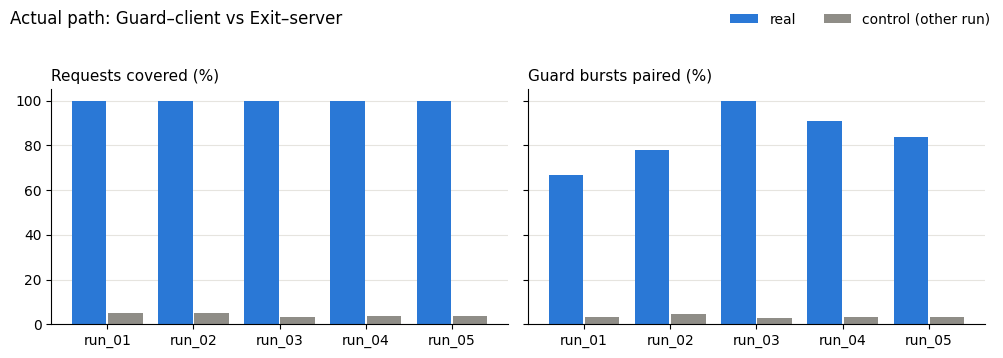

In [6]:
plot(actual, "Actual path: Guard–client vs Exit–server", "a1_actual_path.pdf")

**Reading.**

- **Paths.** All requests left through the same Exit, `exitvaqtnywn`. The response of each request crossed one of two directory authorities, `dasikrbniw` or `daythqtcja`: the two Guards of the conflux legs (part B).
- **Requests.** Every confirmed request is covered: 500/500, against 20.5/500 (4.1%) in the control. When the observer watches the Guard and the Exit that a request really used, timing alone links the two sides of every request.
- **Bursts.** 81.8% of the Guard bursts find a partner, against 3.5% by chance. All the unpaired Guard bursts fall inside a request and go from the Guard to the client: they are pieces of the response. The same response splits into more bursts on the Guard side than on the Exit side (in run_01, 249 bursts for 94 responses on `dasikrbniw`, against 2 bursts per response on the Exit), and the one-to-one pairing leaves the extra pieces without a partner.

### A.2 All the Guard traffic, as in the onion analysis

Same as A.1, but the Guard side keeps the whole Guard capture (all port 9001 traffic, with any peer) instead of only the Guard–client packets. The Exit side is unchanged.

In [7]:
def all_guard_traffic(run, nick):
    """The whole capture of the Guard on port 9001, direction relative to the Guard (as in the onion analysis)."""
    df = DATA[run]["traces"][nick]
    seg = df[(df.sport == GUARD_PORT) | (df.dport == GUARD_PORT)].copy()
    seg["dir"] = np.where(seg.src == node_ip(run, nick), 1, -1)
    return seg

actual_all = table(with_control(actual_path, guard_trace=all_guard_traffic))
actual_all

,run,requests,covered,covered_control,requests_covered_%,requests_covered_control_%,guard_bursts,guard_paired_%,guard_control_%,exit_bursts,exit_paired_%,exit_control_%
0,run_01,100,100,5.2,100.0,5.2,547,36.6,1.9,200,100.0,5.2
1,run_02,100,100,5.0,100.0,5.0,539,49.4,2.2,200,100.0,5.0
2,run_03,100,100,3.2,100.0,3.2,320,62.2,2.0,199,100.0,3.3
3,run_04,100,100,3.5,100.0,3.5,740,50.8,2.0,200,100.0,3.8
4,run_05,100,100,3.5,100.0,3.5,610,49.8,2.0,199,100.0,3.5
5,ALL,500,500,20.5,100.0,4.1,2756,48.8,2.0,998,100.0,4.2


**Reading and comparison with the onion experiment** (pooled over the 5 runs; onion values from the [minimal onion report](../onion-correlation/ONION_CORRELATION_MINIMAL.md)).

| | Clearnet, Guard–client (A.1) | Clearnet, all Guard traffic (A.2) | Onion, two Guards |
|---|---:|---:|---:|
| Guard bursts with a partner | 81.8% of 986 (control 3.5%) | 48.8% of 2756 (control 2.0%) | 54.8% of 1405 (control 2.4%) |
| Requests covered | 100% (500/500; control 4.1%) | 100% (500/500; control 4.1%) | 85.8% (429/500; control 3.1%) |

- **Effect of the segment filter.** The whole Guard capture holds 2.8 times as many bursts. Besides the Guard–client link it contains the Guard–middle link, which carries the same cells a few milliseconds apart, and the rest of the relay's traffic. The share of paired Guard bursts drops from 81.8% to 48.8%; request coverage does not change.
- **Bursts.** Computed the same way (A.2), the share of paired bursts is close to the onion one: 48.8% against 54.8%, with a similar control.
- **Requests.** Coverage is higher than in the onion experiment: 100% against 85.8%. In the onion analysis all 71 uncovered requests are explained by the 1000-byte threshold with a page of a few bytes (`Hello Tor`). Here the page is 10 KB, so the difference says more about the page than about the scenario ([README, choice 4](README.md#4-pagina-da-10-kb-e-soglia-di-1000-byte)).
- **What differs between the two experiments.** The observed segments (Guard–client and Exit–server here, two Guards in onion), the page size, and the nodes: here each request is evaluated with the nodes it actually used, while the onion analysis watched two fixed Guards. Part B shows what changes when the observer watches only one Guard.

## B. What this experiment adds

*(next step)*

## C. Notes for the report

*(next step)*